# Grover search

Grover's algorithm finds a marked item among N in about (π/4)√N oracle calls. Too many iterations overshoot, so the
success probability oscillates with the number of iterations.

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': 'c88add07efb8:7:9e791f',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. Two qubits: one iteration is exact

With N = 4, a single iteration finds the marked state with probability 1.

In [2]:
def grover(n, marked, iterations):
    """OpenQASM 3 Grover search on n qubits for the bitstring `marked` (written q[n-1] ... q[0])."""
    flips = [f"x q[{i}];" for i in range(n) if marked[n - 1 - i] == "0"]
    ctrl = ", ".join(f"q[{i}]" for i in range(n - 1))
    mcz = f"ctrl({n - 1}) @ z {ctrl}, q[{n - 1}];" if n > 1 else "z q[0];"
    diffusion = [*(f"h q[{i}];" for i in range(n)), *(f"x q[{i}];" for i in range(n)), mcz,
                 *(f"x q[{i}];" for i in range(n)), *(f"h q[{i}];" for i in range(n))]
    body = [*(f"h q[{i}];" for i in range(n))]
    for _ in range(iterations):
        body += [*flips, mcz, *flips, *diffusion]
    return f"""OPENQASM 3;
include "stdgates.inc";
qubit[{n}] q;
bit[{n}] c;
""" + "\n".join(body) + "\nc = measure q;\n"

r = run("quantinuum_helios", grover(2, "10", 1), shots=2000)
print(r["result"]["counts"])

{'10': 2000}


## 2. Success oscillates with iterations

For three and four qubits, the success probability rises to a maximum near (π/4)√N iterations and then falls; the ideal value is sin²((2k+1)·arcsin(1/√N)).

In [3]:
rows = []
for n, marked in ((3, "101"), (4, "1011")):
    for k in range(0, 6):
        p = success(run("quantinuum_helios", grover(n, marked, k), shots=20000), [marked])
        rows.append({"qubits": n, "iterations": k, "measured": round(p, 4),
                     "sin^2((2k+1) asin(1/sqrt N))": round(np.sin((2 * k + 1) * np.arcsin(1 / np.sqrt(2 ** n))) ** 2, 4)})
pd.DataFrame(rows).set_index(["qubits", "iterations"])

measured  sin^2((2k+1) asin(1/sqrt N))
qubits iterations                                        
3      0             0.1275                        0.1250
       1             0.7802                        0.7812
       2             0.9471                        0.9453
       3             0.3241                        0.3301
       4             0.0104                        0.0122
       5             0.5445                        0.5480
4      0             0.0637                        0.0625
       1             0.4712                        0.4727
       2             0.9115                        0.9084
       3             0.9637                        0.9613
       4             0.5796                        0.5817
       5             0.1202                        0.1255

## 3. Grover on every twin

Three qubits, two iterations (the optimum), with device noise. The multi-controlled Z compiles into many native entanglers, so the twins separate clearly.

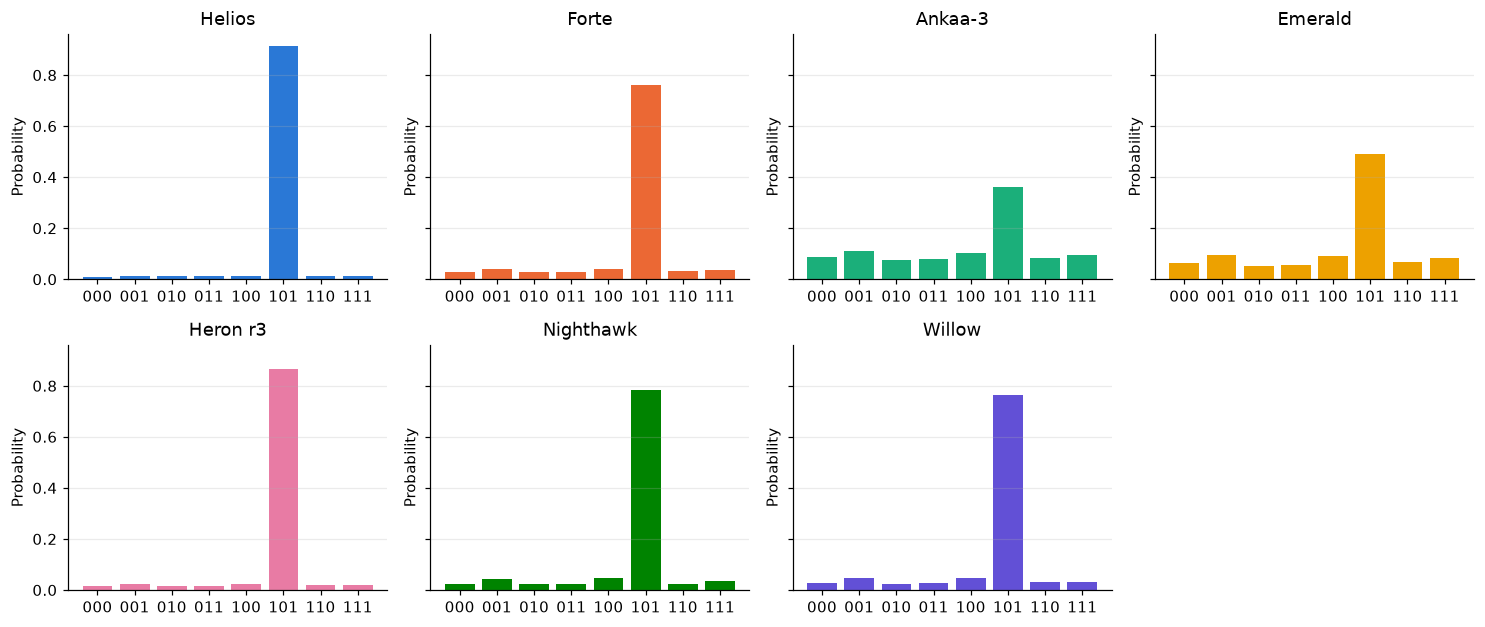

,P(101),native 2Q gates
twin,,
Helios,0.9145,40
Forte,0.7625,40
Ankaa-3,0.3620,58
Emerald,0.4924,60
Heron r3,0.8674,60
Nighthawk,0.7844,59
Willow,0.7654,59


In [4]:
results = {b: run(b, grover(3, "101", 2), shots=20000, noise=True, routing=True) for b in ALL_BACKENDS}
plot_each_twin(results, top=8)
pd.DataFrame([{"twin": NAMES[b], "P(101)": round(success(r, ["101"]), 4),
               "native 2Q gates": r["compilation"]["native_two_qubit_count"]} for b, r in results.items()]).set_index("twin")

## 4. When does noise win?

On a noisy device each extra iteration also adds error. The twin shows whether the best iteration count on hardware is still the ideal one.

In [5]:
rows = []
for k in range(0, 5):
    row = {"iterations": k}
    for b in ("quantinuum_helios", "ionq_forte", "iqm_emerald"):
        row[NAMES[b]] = round(success(run(b, grover(4, "1011", k), shots=20000, noise=True, routing=True), ["1011"]), 4)
    rows.append(row)
pd.DataFrame(rows).set_index("iterations")

,Helios,Forte,Emerald
iterations,,,
0,0.0625,0.0625,0.0636
1,0.4410,0.3280,0.1690
2,0.8051,0.4245,0.1473
3,0.8037,0.3291,0.0929
4,0.4643,0.1787,0.0698


## Takeaways

- Grover's success oscillates exactly as predicted on the ideal twins.
- Multi-controlled gates are expensive in native gates, and the twins show what that costs on each device.